# Integración y convergencia numérica

## Objetivo
Relacionar acumulación con área con signo y medir el error de una regla numérica.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Sumar trapecios

Para integrar $x^2$ en $[0,1]$, la referencia exacta es $1/3$. El trapecio compuesto usa alturas en los extremos de cada subintervalo. Para esta función convexa, las cuerdas quedan por encima de la curva.

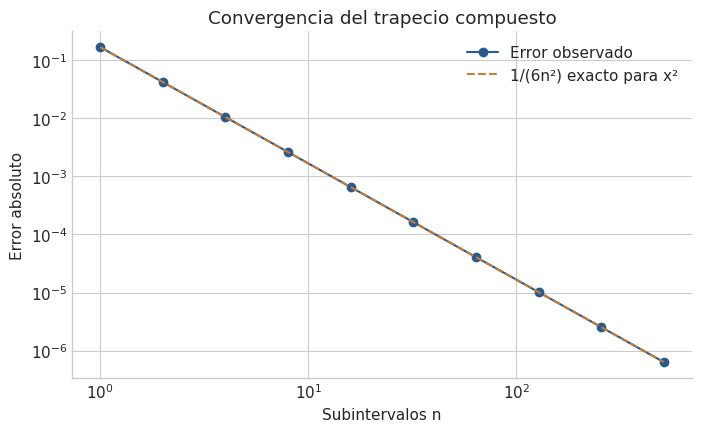

n=1,2,4: [0.5     0.375   0.34375]


In [2]:
def trapecios(f,a,b,n):
    x=np.linspace(a,b,n+1)
    y=f(x)
    return (b-a)/n*(y[0]/2+y[1:-1].sum()+y[-1]/2)
ns=2**np.arange(0,10)
integrales=np.array([trapecios(lambda x:x*x,0,1,int(n)) for n in ns])
errores=np.abs(integrales-1/3)
fig,ax=plt.subplots()
ax.loglog(ns,errores,'o-',label='Error observado')
ax.loglog(ns,1/(6*ns.astype(float)**2),'--',label='1/(6n²) exacto para x²')
ax.set(xlabel='Subintervalos n',ylabel='Error absoluto',title='Convergencia del trapecio compuesto')
ax.legend(); plt.show()
print('n=1,2,4:',integrales[:3])

**Lectura del resultado.** Los valores 0.5, 0.375 y 0.34375 se aproximan a 1/3 desde arriba. El error se divide por cuatro al duplicar n en este ejemplo.

## 2. Área con signo y costo acumulado

$\int_{-1}^1x\,dx=0$, pero $\int_{-1}^1|x|\,dx=1$. En costos, integrar $C\prime(q)=2+0.1q$ entre 0 y 10 añade 25 al costo fijo de 100.

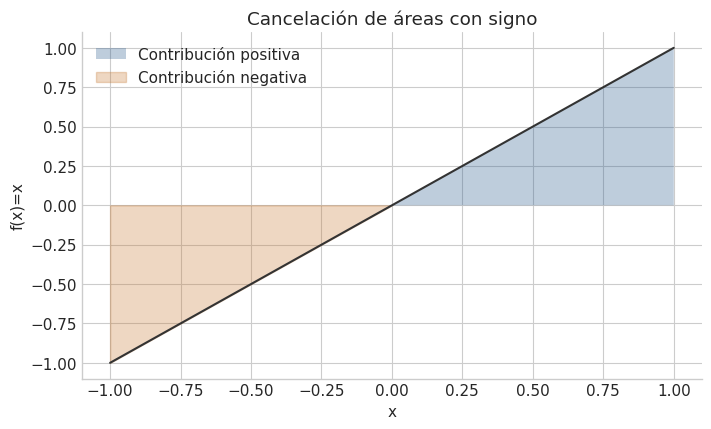

Integral firmada: 3.552713678800501e-17
Costo total: 125.0


In [3]:
x=np.linspace(-1,1,201)
fig,ax=plt.subplots()
ax.plot(x,x,color='#333333')
ax.fill_between(x,0,x,where=x>=0,alpha=.3,label='Contribución positiva')
ax.fill_between(x,0,x,where=x<=0,alpha=.3,color='#C77C36',label='Contribución negativa')
ax.set(xlabel='x',ylabel='f(x)=x',title='Cancelación de áreas con signo')
ax.legend(); plt.show()
print('Integral firmada:',trapecios(lambda x:x,-1,1,100))
print('Costo total:',100+trapecios(lambda q:2+.1*q,0,10,100))

**Lectura del resultado.** Una integral cero no significa que la función sea cero. El costo total incorpora tanto el flujo marginal acumulado como la condición inicial.

## Practica antes de ver la solución

Calcula ∫ de 0 a 2 de 3x² dx. ¿Qué cambia si inviertes los límites?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

La antiderivada es x³: 8−0=8. Al invertir límites se obtiene −8; orientación e interpretación del acumulado importan.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
assert np.allclose(errores,1/(6*ns.astype(float)**2),rtol=1e-8)
assert abs(trapecios(lambda x:x,-1,1,100))<1e-12
assert np.isclose(trapecios(np.abs,-1,1,100),1)
assert np.isclose(100+trapecios(lambda q:2+.1*q,0,10,100),125)
print('Integrales y orden de convergencia: OK')

Integrales y orden de convergencia: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.